# Subscription outcome classification: baseline

Predict whether each customer subscribed (`yes` or `no`) after the call using the recorded call duration and other UCI features. Use a stratified 60/20/20 train/validation/test split and fit preprocessing on training rows only.


In [1]:
from importlib import reload
from scripts import uci_preprocessing as preprocessing_module
load_and_preprocess_uci = reload(preprocessing_module).load_and_preprocess_uci

data = load_and_preprocess_uci(
    seed=42, train_size=0.6, val_size=0.2, test_size=0.2,
    include_duration=True,
)
(
    X_train, X_val, X_test,
    y_train, y_val, y_test,
    X_train_processed, X_val_processed, X_test_processed,
    preprocessor, feature_names,
) = data
assert "duration" in X_train.columns

print("Split sizes:", {"train": len(X_train), "validation": len(X_val), "test": len(X_test)})
print("Processed feature count:", len(feature_names))
print("Positive rates:", {"train": float(round(y_train.mean(), 3)), "validation": float(round(y_val.mean(), 3)), "test": float(round(y_test.mean(), 3))})
print("Processed shapes:", X_train_processed.shape, X_val_processed.shape, X_test_processed.shape)


Split sizes: {'train': 27126, 'validation': 9042, 'test': 9043}
Processed feature count: 52
Positive rates: {'train': 0.117, 'validation': 0.117, 'test': 0.117}
Processed shapes: (27126, 52) (9042, 52) (9043, 52)


## Training and validation

Compare eight classifiers using three stratified training folds. Each fold fits its own preprocessing; the SMOTENC notebook also generates synthetic rows only within that fold's training portion. Evaluate F1, accuracy, precision, recall, and PR-AUC. Select the model with the highest PR-AUC on the validation split, then evaluate it once on the untouched test split. The classification metrics use a 0.5 probability cutoff.


In [2]:
import pandas as pd
pd.options.display.float_format = "{:.3f}".format
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, auc, f1_score, precision_recall_curve,
    precision_score, recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

SEED = 42
CV_FOLDS = 3
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

models = {
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=SEED),
    "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
    "XGBoost": xgb.XGBClassifier(n_estimators=150, n_jobs=2, random_state=SEED),
    "LightGBM": lgb.LGBMClassifier(n_estimators=150, verbosity=-1, n_jobs=2, random_state=SEED),
    "CatBoost": CatBoostClassifier(
        iterations=200, thread_count=2, verbose=0, random_seed=SEED,
        allow_writing_files=False,
    ),
}
models["Stacking ensemble"] = StackingClassifier(
    estimators=[
        ("logistic", clone(models["Logistic regression"])),
        ("forest", clone(models["Random forest"])),
        ("lightgbm", clone(models["LightGBM"])),
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
    stack_method="predict_proba", cv=3, n_jobs=1,
)

def pr_auc_score(y_true, probabilities):
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    return auc(recall, precision)

def metric_row(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "f1": f1_score(y_true, predictions, zero_division=0),
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "pr_auc": pr_auc_score(y_true, probabilities),
    }

def pr_auc_scorer(estimator, X, y_true):
    return pr_auc_score(y_true, estimator.predict_proba(X)[:, 1])

scoring = {
    "f1": "f1", "accuracy": "accuracy", "precision": "precision",
    "recall": "recall", "pr_auc": pr_auc_scorer,
}
cv_rows = []
validation_rows = []
fitted_models = {}
for name, estimator in models.items():
    pipeline = make_pipeline(clone(preprocessor), estimator)
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({
        "model": name,
        **{f"{metric}_mean": scores[f"test_{metric}"].mean() for metric in scoring},
        **{f"{metric}_sd": scores[f"test_{metric}"].std(ddof=1) for metric in scoring},
    })
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline
    validation_rows.append({"model": name, **metric_row(y_val, pipeline.predict_proba(X_val)[:, 1])})
    print(f"Finished {name}")

cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("pr_auc_mean", ascending=False)
validation_results = pd.DataFrame(validation_rows).set_index("model").sort_values("pr_auc", ascending=False)
print("\nThree-fold cross-validation (training split; mean ± SD):")
display(cv_results.round(3))
print("\nValdidation Metrics for Baseline Models:")
display(validation_results.round(3))



Finished Logistic regression
Finished Decision tree
Finished Random forest
Finished Gradient boosting
Finished XGBoost
Finished LightGBM
Finished CatBoost
Finished Stacking ensemble

Three-fold cross-validation (training split; mean ± SD):


,f1_mean,accuracy_mean,precision_mean,recall_mean,pr_auc_mean,f1_sd,accuracy_sd,precision_sd,recall_sd,pr_auc_sd
model,,,,,,,,,,
Stacking ensemble,0.528,0.906,0.635,0.451,0.613,0.006,0.001,0.010,0.006,0.013
CatBoost,0.539,0.906,0.632,0.470,0.609,0.011,0.002,0.013,0.010,0.015
LightGBM,0.535,0.905,0.623,0.469,0.601,0.004,0.001,0.008,0.003,0.014
Random forest,0.464,0.903,0.650,0.362,0.594,0.019,0.001,0.008,0.024,0.010
Gradient boosting,0.497,0.905,0.652,0.401,0.592,0.013,0.002,0.019,0.017,0.016
XGBoost,0.522,0.901,0.602,0.461,0.579,0.011,0.003,0.016,0.008,0.017
Logistic regression,0.442,0.900,0.640,0.338,0.547,0.013,0.003,0.025,0.008,0.021
Decision tree,0.473,0.876,0.469,0.477,0.504,0.013,0.002,0.008,0.021,0.012



Valdidation Metrics for Baseline Models:


,f1,accuracy,precision,recall,pr_auc
model,,,,,
Stacking ensemble,0.544,0.909,0.661,0.462,0.629
LightGBM,0.543,0.908,0.649,0.467,0.621
CatBoost,0.547,0.908,0.646,0.474,0.610
Random forest,0.490,0.905,0.659,0.390,0.610
XGBoost,0.547,0.906,0.629,0.483,0.604
Gradient boosting,0.500,0.906,0.667,0.400,0.589
Logistic regression,0.456,0.902,0.649,0.352,0.550
Decision tree,0.474,0.877,0.476,0.472,0.505


In [3]:
display(validation_results.round(3))

,f1,accuracy,precision,recall,pr_auc
model,,,,,
Stacking ensemble,0.544,0.909,0.661,0.462,0.629
LightGBM,0.543,0.908,0.649,0.467,0.621
CatBoost,0.547,0.908,0.646,0.474,0.610
Random forest,0.490,0.905,0.659,0.390,0.610
XGBoost,0.547,0.906,0.629,0.483,0.604
Gradient boosting,0.500,0.906,0.667,0.400,0.589
Logistic regression,0.456,0.902,0.649,0.352,0.550
Decision tree,0.474,0.877,0.476,0.472,0.505


## Selected model: held-out test evaluation

Select by validation PR-AUC and report final performance on the unchanged test data.


In [4]:
best_model_name = validation_results.index[0]
best_model = fitted_models[best_model_name]
test_results = pd.DataFrame(
    [metric_row(y_test, best_model.predict_proba(X_test)[:, 1])],
    index=[best_model_name],
)
print("Selected model:", best_model_name)
print("Held-out test metrics:")
display(test_results.round(3))

from sklearn.metrics import confusion_matrix

test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= 0.5).astype(int)
test_confusion = pd.DataFrame(
    confusion_matrix(y_test, test_predictions),
    index=["Actual no", "Actual yes"],
    columns=["Predicted no", "Predicted yes"],
)
print("Test confusion matrix (customer counts):")
display(test_confusion)


Selected model: Stacking ensemble
Held-out test metrics:


,f1,accuracy,precision,recall,pr_auc
Stacking ensemble,0.555,0.911,0.668,0.474,0.650


Test confusion matrix (customer counts):


,Predicted no,Predicted yes
Actual no,7736,249
Actual yes,556,502


## Results at a glance

The first chart compares PR-AUC across models; the second shows validation precision and recall at the 0.5 cutoff.


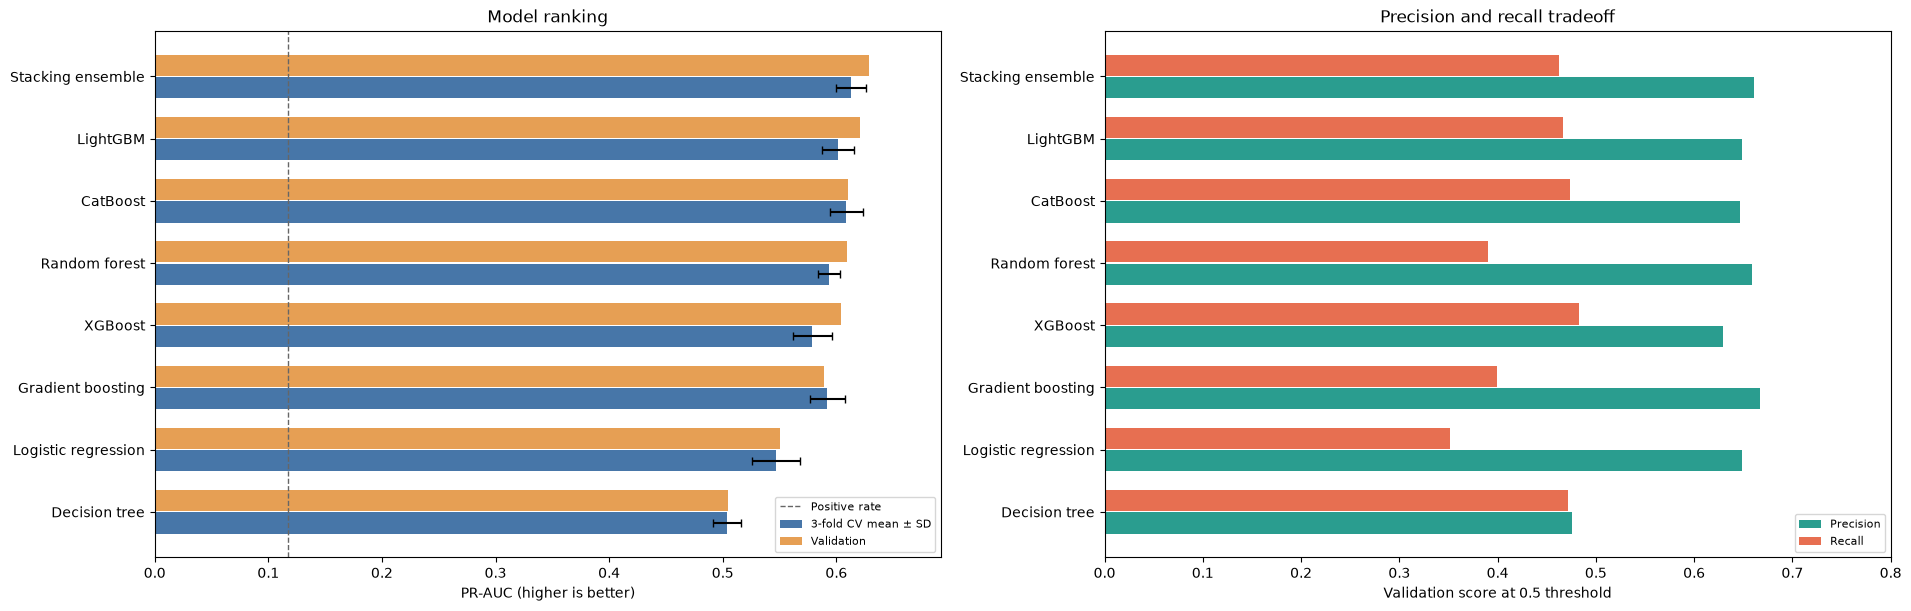

In [5]:
import matplotlib.pyplot as plt
import numpy as np

order = validation_results.index[::-1]
positions = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(19, 6), layout="constrained")

# PR-AUC is the primary ranking metric for this imbalanced target.
axes[0].barh(positions - 0.18, cv_results.loc[order, "pr_auc_mean"],
             height=0.34, xerr=cv_results.loc[order, "pr_auc_sd"],
             capsize=3, label="3-fold CV mean ± SD", color="#4776A8")
axes[0].barh(positions + 0.18, validation_results.loc[order, "pr_auc"],
             height=0.34, label="Validation", color="#E69F54")
axes[0].axvline(y_train.mean(), color="#666666", linestyle="--", linewidth=1,
                label="Positive rate")
axes[0].set_yticks(positions, order)
axes[0].set_xlim(0, max(0.55, validation_results["pr_auc"].max() * 1.10))
axes[0].set_xlabel("PR-AUC (higher is better)")
axes[0].set_title("Model ranking")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].barh(positions - 0.18, validation_results.loc[order, "precision"],
             height=0.34, label="Precision", color="#2A9D8F")
axes[1].barh(positions + 0.18, validation_results.loc[order, "recall"],
             height=0.34, label="Recall", color="#E76F51")
axes[1].set_yticks(positions, order)
axes[1].set_xlim(0, 0.8)
axes[1].set_xlabel("Validation score at 0.5 threshold")
axes[1].set_title("Precision and recall tradeoff")
axes[1].legend(fontsize=8, loc="lower right")

plt.show()


## More ways to read the results

The validation charts compare F1 and accuracy across all eight models. The dashed accuracy line is the score from always predicting the majority class. The test charts show how the selected model trades precision against recall as the cutoff changes, and how many subscribers and non-subscribers it classifies correctly at the 0.5 cutoff. The test set is used only for this final evaluation.


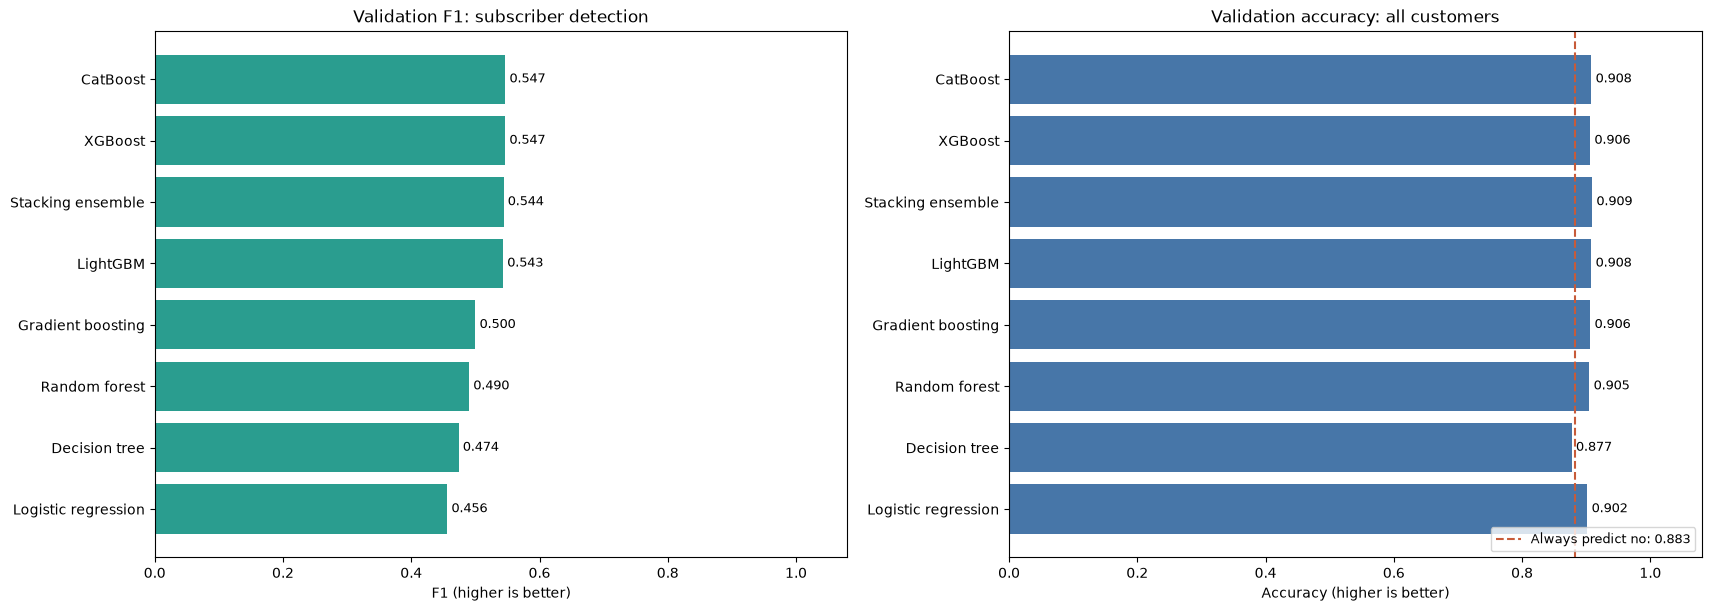

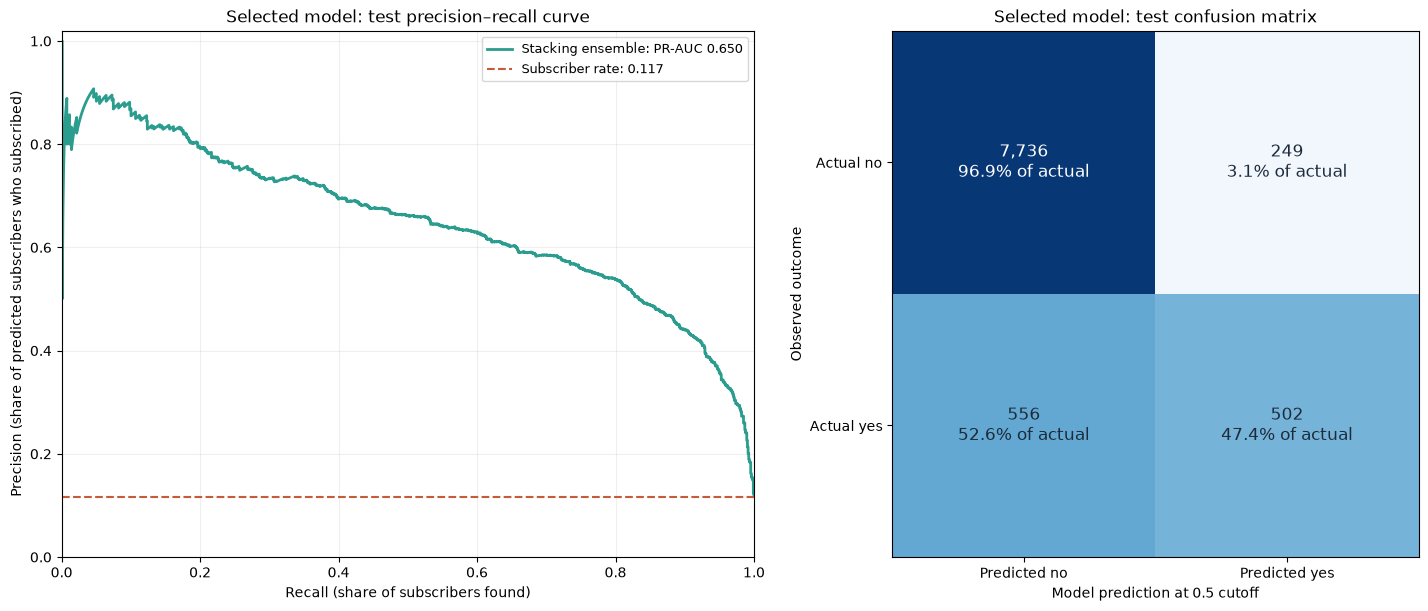

In [6]:
from sklearn.metrics import precision_recall_curve

order = validation_results.sort_values("f1").index
fig, axes = plt.subplots(1, 2, figsize=(17, 6), layout="constrained")

for ax, metric, color, title in [
    (axes[0], "f1", "#2A9D8F", "Validation F1: subscriber detection"),
    (axes[1], "accuracy", "#4776A8", "Validation accuracy: all customers"),
]:
    values = validation_results.loc[order, metric]
    bars = ax.barh(order, values, color=color)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel(f"{metric.upper() if metric == 'f1' else metric.title()} (higher is better)")
    ax.set_title(title)
axes[1].axvline(max(y_val.mean(), 1 - y_val.mean()), color="#C75B39",
                linestyle="--", linewidth=1.5,
                label=f"Always predict no: {1 - y_val.mean():.3f}")
axes[1].legend(loc="lower right", fontsize=9)
plt.show()

precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probabilities)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")

axes[0].plot(recall_curve, precision_curve, color="#2A9D8F", linewidth=2,
             label=f"{best_model_name}: PR-AUC {test_results.loc[best_model_name, 'pr_auc']:.3f}")
axes[0].axhline(y_test.mean(), color="#C75B39", linestyle="--", linewidth=1.5,
                label=f"Subscriber rate: {y_test.mean():.3f}")
axes[0].set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Recall (share of subscribers found)",
            ylabel="Precision (share of predicted subscribers who subscribed)",
            title="Selected model: test precision–recall curve")
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(alpha=0.2)

counts = test_confusion.to_numpy()
row_shares = counts / counts.sum(axis=1, keepdims=True)
axes[1].imshow(row_shares, cmap="Blues", vmin=0, vmax=1)
for row in range(2):
    for col in range(2):
        axes[1].text(col, row, f"{counts[row, col]:,}\n{row_shares[row, col]:.1%} of actual",
                     ha="center", va="center", fontsize=12,
                     color="white" if row_shares[row, col] > 0.55 else "#1D2B3A")
axes[1].set_xticks([0, 1], ["Predicted no", "Predicted yes"])
axes[1].set_yticks([0, 1], ["Actual no", "Actual yes"])
axes[1].set_xlabel("Model prediction at 0.5 cutoff")
axes[1].set_ylabel("Observed outcome")
axes[1].set_title("Selected model: test confusion matrix")
plt.show()


## Interpretation

**Evaluation and predictability.** Stacking had the highest validation PR-AUC and scored **0.650 PR-AUC, 0.555 F1, and 0.911 accuracy** on the untouched test split. At the 0.5 cutoff, it identified **502 of 1,058 subscribers** (recall **0.474**) and incorrectly flagged **249 non-subscribers** (precision **0.668**). Accuracy is less revealing because non-subscribers are the large majority; recall and PR-AUC show how well the model finds and ranks subscribers.

**Business meaning.** This model uses the **full completed-call duration** to classify subscription outcomes in recorded interactions. It can support retrospective campaign analysis or flag records for review. Its score does not show that a customer should be called, and these metrics alone do not establish campaign profit or causal impact.

**Synthetic-data comparison.** The SMOTENC experiment found 13 more subscribers at the same cutoff, but also flagged 44 more non-subscribers and had lower PR-AUC (**0.636**). Thus, the added synthetic rows did not improve overall ranking in this test. A conditional tabular GAN could be tested because it may learn mixed numeric/categorical dependencies and generate more varied subscriber examples than SMOTENC's local interpolation. This is a hypothesis, not a guaranteed gain; train the GAN on training rows only and compare on the same untouched validation and test splits. [CTGAN paper](https://papers.neurips.cc/paper_files/paper/2019/hash/254ed7d2de3b23ab10936522dd547b78-Abstract.html)
